In [1]:
from oceanum.datamesh import Connector

datamesh = Connector()

DATASET = "cmems_mod_glo_phy-thetao_anfc_0-083deg_pt6h-i"
BBOX    = [160.5, -52.5, 185.5, -30.5]          # what download_input.py asks for (0-360)
TIMES   = ["2025-01-01", "2025-01-01T06:00"]    # short window, quick test

west = datamesh.query(
    datasource=DATASET,
    variables=["thetao"],
    timefilter={"type": "range", "times": TIMES},
    geofilter={"type": "bbox", "geom": BBOX},
)

print(west.sizes)
print(float(west.longitude.min()), "->", float(west.longitude.max()))

Frozen({'time': 2, 'elevation': 50, 'latitude': 265, 'longitude': 234})
160.5 -> 179.91668701171875


In [1]:
import sys
sys.path.insert(0, "/home/nn411/Projects/OceanAtm/Moana-2.0/Scripts")   # Scripts/clm after you reorganise
import pandas as pd
from oceanum.datamesh import Connector
from download_input_new import split_at_seam
from download_bry import query_bbox

dm = Connector()
src = {"DATASOURCE": "cmems_mod_glo_phy-thetao_anfc_0-083deg_pt6h-i",
       "VARIABLES": ["thetao"], "LON_CONVENTION": "-180_180"}

box = [178.0, -40.0, -178.0, -39.0]          # 178°E to 182°E, written in CMEMS convention
print("queries sent:", split_at_seam(box, "-180_180"))

t = pd.Timestamp("2026-01-01")
old = dm.query(datasource=src["DATASOURCE"], variables=src["VARIABLES"],          # old way: one box, 0-360
               geofilter={"type": "bbox", "geom": [178.0, -40.0, 182.0, -39.0]},
               timefilter={"type": "range", "times": [t, t]})
new = query_bbox(dm, src, box, t, t)                                              # new way: split and joined

for name, ds in [("old", old), ("new", new)]:
    lon = ds.longitude.values % 360 if name == "old" else ds.longitude.values
    print(f"{name}: lon {lon.min():.2f} to {lon.max():.2f}  ({len(lon)} points)")

queries sent: [[178.0, -40.0, 180.0, -39.0], [-180.0, -40.0, -178.0, -39.0]]
old: lon 178.00 to 179.92  (24 points)
new: lon 178.00 to 182.00  (49 points)


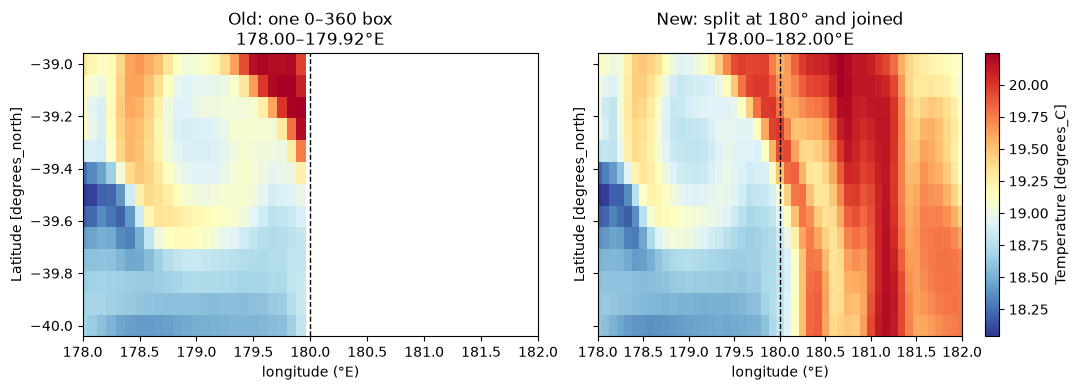

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, ds, name in [(axes[0], old, "Old: one 0–360 box"), (axes[1], new, "New: split at 180° and joined")]:
    ds = ds.assign_coords(longitude=ds.longitude % 360).sortby("longitude")
    sst = ds["thetao"].isel(time=0).sel(elevation=ds.elevation.max())      # surface level
    sst.plot(ax=ax, x="longitude", cmap="RdYlBu_r", add_colorbar=(ax is axes[1]))
    ax.axvline(180, color="k", ls="--", lw=1)
    ax.set_xlim(178, 182)
    ax.set_title(f"{name}\n{float(sst.longitude.min()):.2f}–{float(sst.longitude.max()):.2f}°E")
    ax.set_xlabel("longitude (°E)")
plt.tight_layout()
plt.savefig("/home/nn411/Projects/OceanAtm/Moana-2.0/Figures/seam_fix_test.png", dpi=150)
plt.show()

/cache/home/nn411/miniforge3/envs/moana_python/lib/python3.14/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/cache/home/nn411/miniforge3/envs/moana_python/lib/python3.14/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


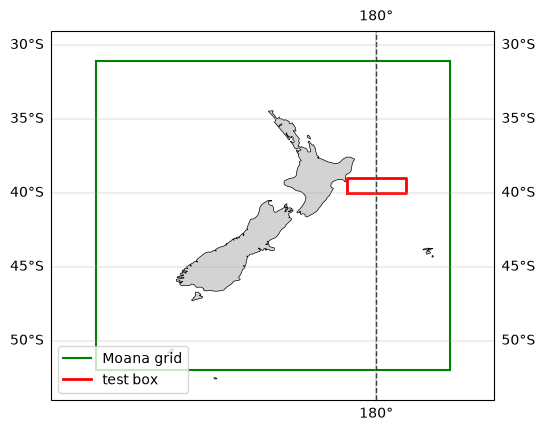

In [3]:
import cartopy.crs as ccrs, cartopy.feature as cfeature
import matplotlib.pyplot as plt, numpy as np, xarray as xr

g = xr.open_dataset("/projects/f_omg_1/moa/moana/grid/moana_grid_N50.nc")
glon, glat = g.lon_rho.values % 360, g.lat_rho.values

ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.coastlines(lw=0.5)
for e in (np.s_[0, :], np.s_[-1, :], np.s_[:, 0], np.s_[:, -1]):
    ax.plot(glon[e], glat[e], "g", transform=ccrs.PlateCarree(), label="Moana grid" if e == np.s_[0, :] else None)
ax.plot([178, 182, 182, 178, 178], [-40, -40, -39, -39, -40], "r", lw=2, transform=ccrs.PlateCarree(), label="test box")
ax.axvline(0, color="k", ls="--", lw=1)          # 180° (centred projection)
ax.set_extent([158, 188, -54, -29], crs=ccrs.PlateCarree())
ax.gridlines(draw_labels=True, lw=0.3)
ax.legend(loc="lower left")
plt.savefig("/home/nn411/Projects/OceanAtm/Moana-2.0/Figures/seam_test_location.png", dpi=150, bbox_inches="tight")
plt.show()

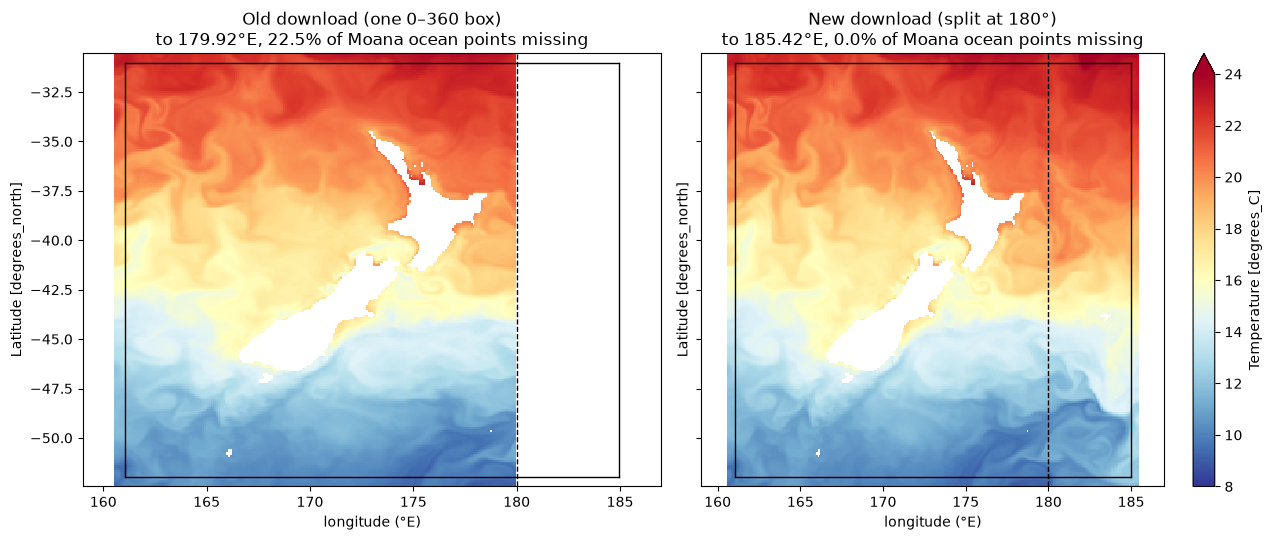

In [5]:
import sys
sys.path.insert(0, "/home/nn411/Projects/OceanAtm/Moana-2.0/Scripts")
import numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
from oceanum.datamesh import Connector
from download_input_new import bbox_from_grid
from download_bry import query_bbox

GRID = "/projects/f_omg_1/moa/moana/grid/moana_grid_N50.nc"
dm = Connector()
src = {"DATASOURCE": "cmems_mod_glo_phy-thetao_anfc_0-083deg_pt6h-i",
       "VARIABLES": ["thetao"], "LON_CONVENTION": "-180_180"}
t = pd.Timestamp("2026-01-01")

new_box = bbox_from_grid(GRID, convention="-180_180")              # [160.5, …, -174.5, …]
old_box = [new_box[0], new_box[1], new_box[2] % 360, new_box[3]]   # [160.5, …, 185.5, …] as the old script did

old = dm.query(datasource=src["DATASOURCE"], variables=src["VARIABLES"],
               geofilter={"type": "bbox", "geom": old_box},
               timefilter={"type": "range", "times": [t, t]})
new = query_bbox(dm, src, new_box, t, t)

g = xr.open_dataset(GRID)
glon, glat = g.lon_rho.values % 360, g.lat_rho.values
ocean = g.mask_rho.values == 1

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, ds, name in [(axes[0], old, "Old download (one 0–360 box)"), (axes[1], new, "New download (split at 180°)")]:
    ds = ds.assign_coords(longitude=ds.longitude % 360).sortby("longitude")
    sst = ds["thetao"].isel(time=0).sel(elevation=ds.elevation.max())
    lonmax = float(sst.longitude.max())
    missing = 100 * (1 - (ocean & (glon <= lonmax)).sum() / ocean.sum())
    sst.plot(ax=ax, x="longitude", cmap="RdYlBu_r", vmin=8, vmax=24, add_colorbar=(ax is axes[1]))
    for e in (np.s_[0, :], np.s_[-1, :], np.s_[:, 0], np.s_[:, -1]):
        ax.plot(glon[e], glat[e], "k", lw=1)
    ax.axvline(180, color="k", ls="--", lw=1)
    ax.set_xlim(159, 187)
    ax.set_title(f"{name}\nto {lonmax:.2f}°E, {missing:.1f}% of Moana ocean points missing")
    ax.set_xlabel("longitude (°E)")
plt.tight_layout()
plt.savefig("/home/nn411/Projects/OceanAtm/Moana-2.0/Figures/seam_fix_full_domain.png", dpi=150)
plt.show()